In [13]:
import pandas as pd

In [15]:
df = pd.read_csv("ncr_ride_bookings.csv")

In [17]:
df.head()
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  1050

Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64

In [21]:
import numpy as np

df.replace("null", np.nan, inplace=True)
df = df.fillna(0)

In [23]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,0.0,0.0,...,0,0.0,0,0.0,0,0.0,0.00,0.0,0.0,0
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,0,0.0,0,1.0,Vehicle Breakdown,237.0,5.73,0.0,0.0,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,0,0.0,0,0.0,0,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,0,0.0,0,0.0,0,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,0,0.0,0,0.0,0,737.0,48.21,4.1,4.3,UPI


In [25]:
def classify_ride(status):
    if status == "Completed":
        return "Success"
    elif status in ["No Driver Found", "Incomplete"]:
        return "Failure"
    elif "Cancelled" in status:
        return "Cancelled"
    else:
        return "Other"

df["Ride Outcome"] = df["Booking Status"].apply(classify_ride) #To classify rides based on booking status 


In [27]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Ride Outcome
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,0.0,0.0,...,0.0,0,0.0,0,0.0,0.00,0.0,0.0,0,Failure
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,0.0,0,1.0,Vehicle Breakdown,237.0,5.73,0.0,0.0,UPI,Failure
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,0.0,0,0.0,0,627.0,13.58,4.9,4.9,Debit Card,Success
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,0.0,0,0.0,0,416.0,34.02,4.6,5.0,UPI,Success
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,0.0,0,0.0,0,737.0,48.21,4.1,4.3,UPI,Success


In [29]:
numeric_cols = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').round(2)


In [31]:
text_cols = ['Booking Status', 'Payment Method', 'Vehicle Type', 'Pickup Location', 'Drop Location']
for col in text_cols:
    df[col] = df[col].astype(str)


In [33]:
df.to_csv("rides_cleaned.csv", index=False)


In [35]:
# Basic info
print(df.describe())  # numeric columns summary
print(df['Booking Status'].value_counts())  # count per status
print(df['Ride Outcome'].value_counts())  # count per outcome


            Avg VTAT       Avg CTAT  Cancelled Rides by Customer  \
count  150000.000000  150000.000000                150000.000000   
mean        7.864407      19.821753                     0.070000   
std         4.230640      15.452834                     0.255148   
min         0.000000       0.000000                     0.000000   
25%         4.700000       0.000000                     0.000000   
50%         7.800000      22.000000                     0.000000   
75%        11.000000      32.900000                     0.000000   
max        20.000000      45.000000                     1.000000   

       Cancelled Rides by Driver  Incomplete Rides  Booking Value  \
count              150000.000000     150000.000000  150000.000000   
mean                    0.180000          0.060000     345.641220   
std                     0.384189          0.237488     403.423487   
min                     0.000000          0.000000       0.000000   
25%                     0.000000          

In [39]:
# Convert 'Time' column to datetime
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S', errors='coerce').dt.time

# Extract hour
df['Hour'] = df['Time'].apply(lambda x: x.hour if pd.notnull(x) else np.nan)



In [41]:
# Rides per day
rides_per_day = df.groupby('Date').size()
print(rides_per_day)

# Rides by hour
df['Hour'] = df['Time'].apply(lambda x: x.hour if pd.notnull(x) else np.nan)
rides_per_hour = df.groupby('Hour').size()
print(rides_per_hour)


Date
2024-01-01    414
2024-01-02    389
2024-01-03    384
2024-01-04    414
2024-01-05    416
             ... 
2024-12-26    369
2024-12-27    431
2024-12-28    391
2024-12-29    417
2024-12-30    386
Length: 365, dtype: int64
Hour
0      1373
1      1360
2      1339
3      1383
4      1321
5      2786
6      4160
7      5450
8      6861
9      8234
10     9577
11     8390
12     7006
13     5470
14     7031
15     8202
16     9633
17    11044
18    12397
19    11047
20     9630
21     8103
22     5441
23     2762
dtype: int64


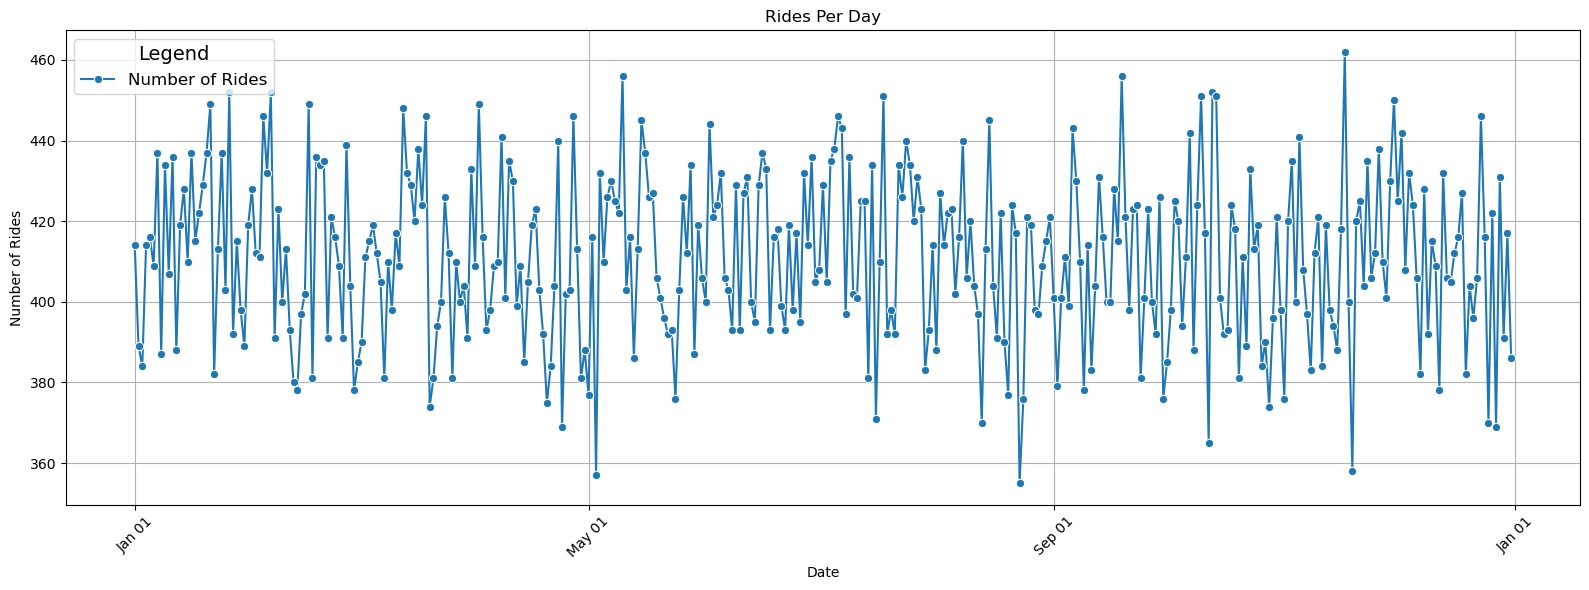

In [53]:
# Visualisation of Rides Per Day 
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

plt.figure(figsize=(16,6))  # wider figure for horizontal spacing
sns.lineplot(x=rides_per_day.index, y=rides_per_day.values, marker='o', label='Number of Rides')

plt.title('Rides Per Day')
plt.xlabel('Date')
plt.ylabel('Number of Rides')

# Format dates and auto space ticks
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d')) 
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5)) 

plt.xticks(rotation=45)
plt.grid(True)
plt.legend(title='Legend', fontsize=12, title_fontsize=14, loc='upper left')

plt.tight_layout()  # auto-adjust spacing
plt.show()


In [140]:
status_counts = df['Ride Outcome'].value_counts(normalize=True) * 100
print(status_counts)

Ride Outcome
Success      62.0
Cancelled    25.0
Failure      13.0
Name: proportion, dtype: float64


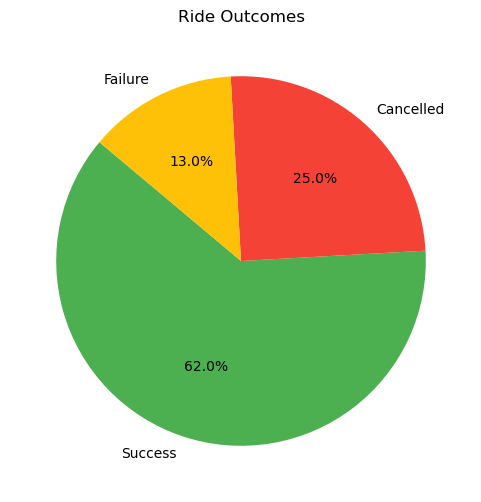

In [67]:
ride_outcome_counts = df['Ride Outcome'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(ride_outcome_counts, labels=ride_outcome_counts.index, autopct='%1.1f%%', startangle=140, colors=['#4CAF50','#F44336','#FFC107'])
plt.title('Ride Outcomes')
plt.show()


C:\Users\khush\AppData\Local\Temp\ipykernel_23384\2870018961.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rides_per_hour.index, y=rides_per_hour.values, palette='viridis')


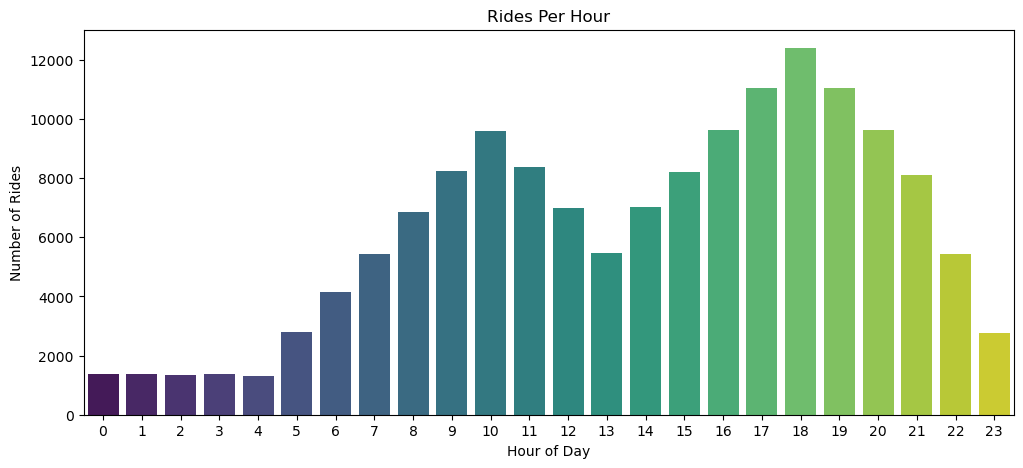

In [65]:
#Rides per hour
plt.figure(figsize=(12,5))
sns.barplot(x=rides_per_hour.index, y=rides_per_hour.values, palette='viridis')
plt.title('Rides Per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Rides')
plt.show()

<Figure size 1200x600 with 0 Axes>

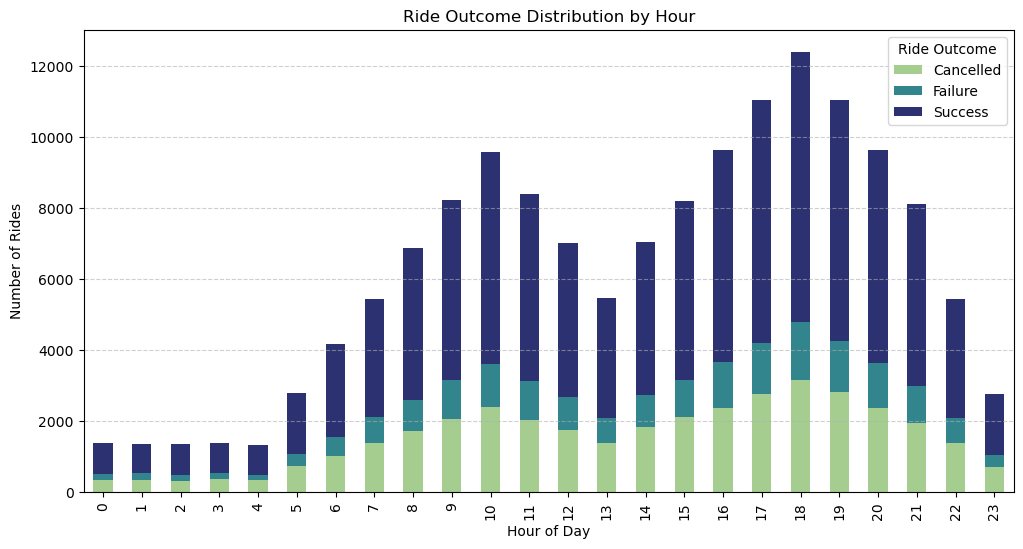

In [104]:
# Count each outcome per hour
ride_outcomes = df.groupby(['Hour', 'Ride Outcome']).size().unstack(fill_value=0)

plt.figure(figsize=(12,6))
ride_outcomes.plot(kind='bar', stacked=True, colormap='crest', figsize=(12,6))
plt.title('Ride Outcome Distribution by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Rides')
plt.legend(title='Ride Outcome')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


C:\Users\khush\AppData\Local\Temp\ipykernel_23384\1728790172.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cancel_by_hour.index, y=cancel_by_hour.values, palette='Reds')


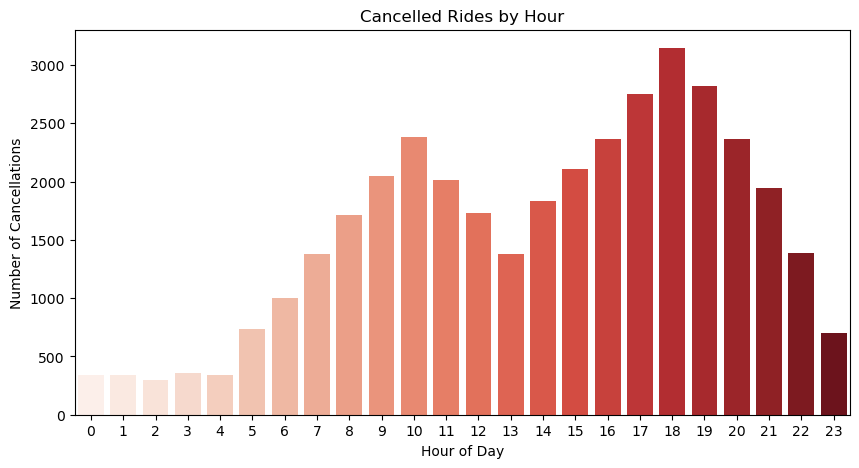

In [121]:
# #Cancellation Behavior by Hour
cancel_by_hour = df[
    df['Ride Outcome'].str.contains('cancel', case=False, na=False)
].groupby('Hour').size()

plt.figure(figsize=(10,5))
sns.barplot(x=cancel_by_hour.index, y=cancel_by_hour.values, palette='Reds')
plt.title('Cancelled Rides by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Cancellations')
plt.show()

In [142]:
revenue_per_hour = df.groupby('Hour')['Booking Value'].sum()
revenue_per_day = df.groupby('Date')['Booking Value'].sum()
print(revenue_per_hour, revenue_per_day)

Hour
0      477304.0
1      467167.0
2      475840.0
3      469813.0
4      454992.0
5      930721.0
6     1471059.0
7     1851902.0
8     2394391.0
9     2891944.0
10    3342593.0
11    2905343.0
12    2424257.0
13    1858436.0
14    2389385.0
15    2818707.0
16    3323600.0
17    3857680.0
18    4268079.0
19    3714520.0
20    3339546.0
21    2887604.0
22    1857020.0
23     974280.0
Name: Booking Value, dtype: float64 Date
2024-01-01    124057.0
2024-01-02    113427.0
2024-01-03    116982.0
2024-01-04    117045.0
2024-01-05    133692.0
                ...   
2024-12-26    122357.0
2024-12-27    137012.0
2024-12-28    187391.0
2024-12-29    214951.0
2024-12-30    118635.0
Name: Booking Value, Length: 365, dtype: float64


### Time-Based Performance

**Findings:**
- Evening rides (17:00–22:00) have the highest completion rate and highest cancellation rate.

**Recommendations:**
- Introduce **Morning Completion Bonus** for drivers to boost supply between 8–9 AM.
- Enable a **“Schedule Morning Ride”** feature for customers to pre-lock drivers.


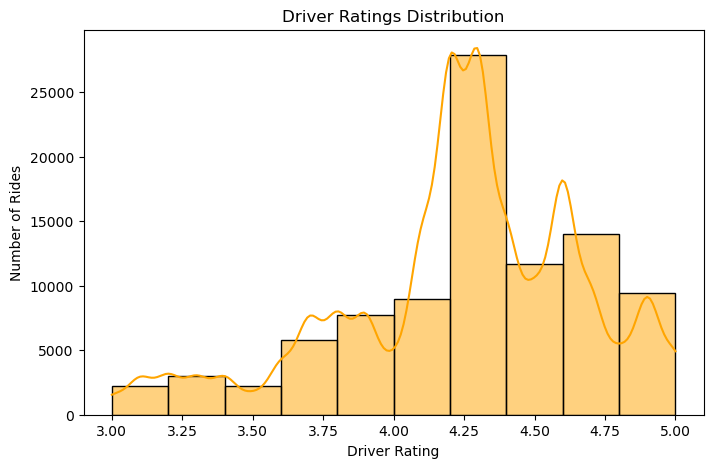

In [75]:
#Driver Ratings
plt.figure(figsize=(8,5))
sns.histplot(df[df['Driver Ratings'] != 0]['Driver Ratings'], bins=10, kde=True, color='orange')
plt.title('Driver Ratings Distribution')
plt.xlabel('Driver Rating')
plt.ylabel('Number of Rides')
plt.show()

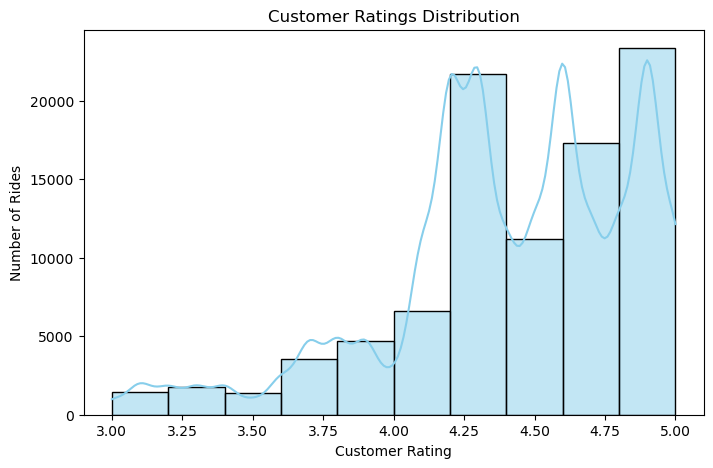

In [73]:
#Customer Ratings
plt.figure(figsize=(8,5))
sns.histplot(df[df['Customer Rating'] != 0]['Customer Rating'], bins=10, kde=True, color='skyblue') # Filter out zeros
plt.title('Customer Ratings Distribution')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Rides')
plt.show()

C:\Users\khush\AppData\Local\Temp\ipykernel_23384\4202276421.py:6: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df_filtered.pivot_table(


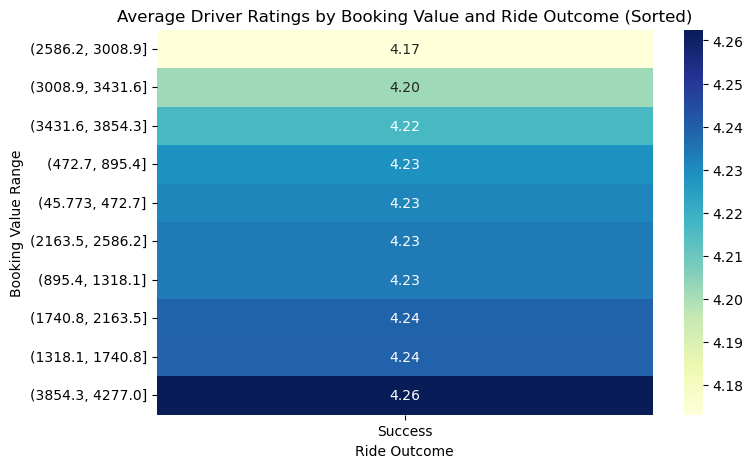

In [87]:
# Filter and bin booking values
df_filtered = df[df['Driver Ratings'] != 0].copy()
df_filtered['Value Bin'] = pd.cut(df_filtered['Booking Value'], bins=10)

# Create pivot table
pivot = df_filtered.pivot_table(
    index='Value Bin',
    columns='Ride Outcome',
    values='Driver Ratings',
    aggfunc='mean'
)

# Calculate overall mean across outcomes for sorting
pivot['Average'] = pivot.mean(axis=1)

# Sort by the average rating
pivot = pivot.sort_values(by='Average', ascending=True)

# Drop helper column before plotting
pivot = pivot.drop(columns='Average')

# Plot heatmap
plt.figure(figsize=(8,5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap='YlGnBu')
plt.title('Average Driver Ratings by Booking Value and Ride Outcome (Sorted)')
plt.ylabel('Booking Value Range')
plt.xlabel('Ride Outcome')
plt.show()

C:\Users\khush\AppData\Local\Temp\ipykernel_23384\1061003656.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_counts.index, y=payment_counts.values, palette='Set2')


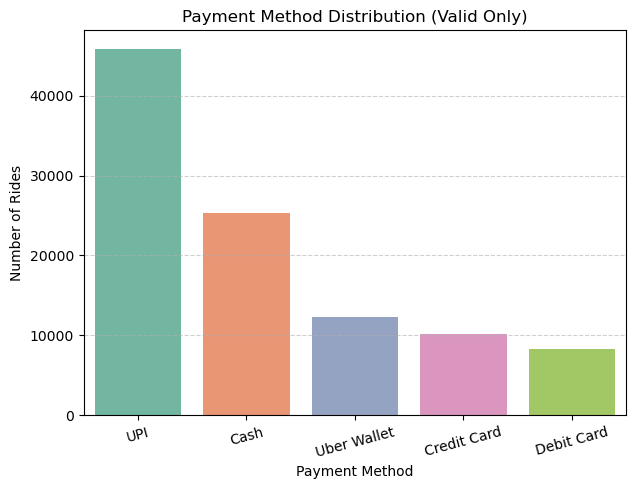

In [91]:
# Filter out invalid or missing payment methods
df_payment = df[df['Payment Method'].notna() & (df['Payment Method'] != 0) & (df['Payment Method'] != '0') & (df['Payment Method'] != '')]

# Count valid payment methods
payment_counts = df_payment['Payment Method'].value_counts()

# Plot
plt.figure(figsize=(7,5))
sns.barplot(x=payment_counts.index, y=payment_counts.values, palette='Set2')
plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Rides')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

C:\Users\khush\AppData\Local\Temp\ipykernel_23384\1926568787.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=route_values.values, y=route_values.index, palette='YlGnBu_r')


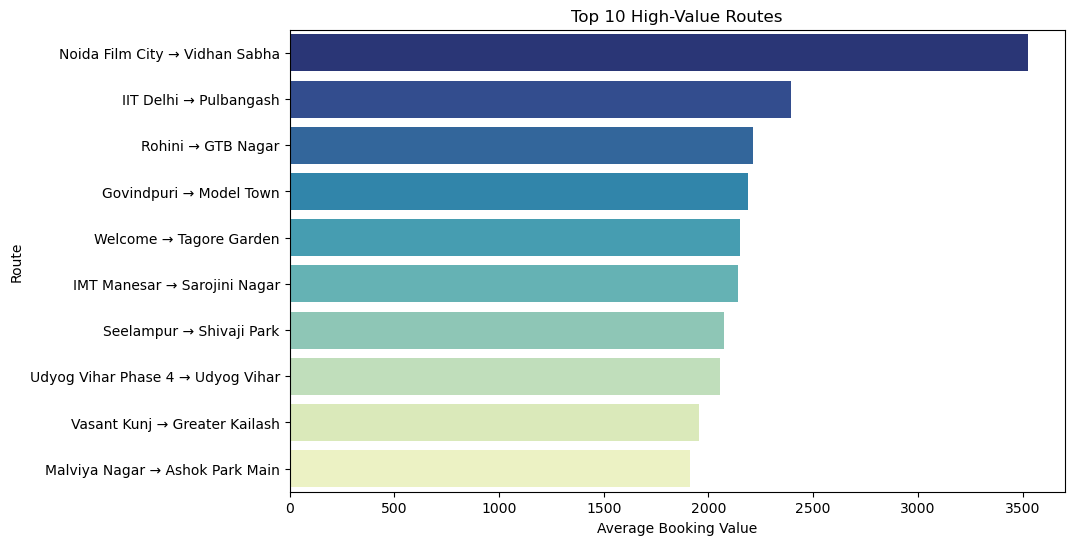

In [99]:
# Average booking value per route
df['Route'] = df['Pickup Location'] + " → " + df['Drop Location']
route_values = df.groupby('Route')['Booking Value'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=route_values.values, y=route_values.index, palette='YlGnBu_r')
plt.title('Top 10 High-Value Routes')
plt.xlabel('Average Booking Value')
plt.ylabel('Route')
plt.show()


### Payment & Pricing Behavior

**Findings:**
- UPI is the dominant payment method.
- Routes like *Noida Film City-Vidhan Sabha* and *IIT Delhi-Pulbangash* have consistently high booking values.

**Recommendations:**
- Introduce **UPI-only cashback** or **Ride 5, Get 1 Free** programs to grow loyal, cashless riders.
- Stabilize prices in premium routes to ensure repeat usage.
- Offer subscription rides or corporate packages to retain daily commuters.
